# LAB 3 

### Question 1: 

It is a regression problem as we try to predict a specific continuous value (number of passenger). It is also a supervised problem as the target value is already known.

### Question 2 : 

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 

df = pd.read_csv("train.csv.bz2")
print('df.info : ')
df.head()

df.info : 


,DateOfDeparture,Departure,Arrival,WeeksToDeparture,log_PAX,std_wtd
0,2012-06-19,ORD,DFW,12.875000,12.331296,9.812647
1,2012-09-10,LAS,DEN,14.285714,10.775182,9.466734
2,2012-10-05,DEN,LAX,10.863636,11.083177,9.035883
3,2011-10-09,ATL,ORD,11.480000,11.169268,7.990202
4,2012-02-21,DEN,SFO,11.450000,11.269364,9.517159


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8902 entries, 0 to 8901
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   DateOfDeparture   8902 non-null   str    
 1   Departure         8902 non-null   str    
 2   Arrival           8902 non-null   str    
 3   WeeksToDeparture  8902 non-null   float64
 4   log_PAX           8902 non-null   float64
 5   std_wtd           8902 non-null   float64
dtypes: float64(3), str(3)
memory usage: 556.5 KB


The types of the columns are shown above. We'll probably need to change the string values later on. 

### Question 3 : 

In [3]:
from pandas.tseries.holiday import USFederalHolidayCalendar # for holidays

df['DateOfDeparture'] = pd.to_datetime(df['DateOfDeparture'])
df.head()
df['day'] = df['DateOfDeparture'].dt.day
df['weekday'] = df['DateOfDeparture'].dt.weekday + 1 
df['week'] = df['DateOfDeparture'].dt.isocalendar().week.astype(int)
df['month'] = df['DateOfDeparture'].dt.month
df['year'] = df['DateOfDeparture'].dt.year


df['is_weekend'] = (df['weekday'] >= 6).astype(int)

cal = USFederalHolidayCalendar()
holidays = cal.holidays(start= df['DateOfDeparture'].min(), end= df['DateOfDeparture'].max())
df['is_holiday'] = (df['DateOfDeparture'].isin(holidays)).astype(int)

df.head()


,DateOfDeparture,Departure,Arrival,WeeksToDeparture,log_PAX,std_wtd,day,weekday,week,month,year,is_weekend,is_holiday
0,2012-06-19,ORD,DFW,12.875000,12.331296,9.812647,19,2,25,6,2012,0,0
1,2012-09-10,LAS,DEN,14.285714,10.775182,9.466734,10,1,37,9,2012,0,0
2,2012-10-05,DEN,LAX,10.863636,11.083177,9.035883,5,5,40,10,2012,0,0
3,2011-10-09,ATL,ORD,11.480000,11.169268,7.990202,9,7,40,10,2011,1,0
4,2012-02-21,DEN,SFO,11.450000,11.269364,9.517159,21,2,8,2,2012,0,0


### Question 4 : 

In [4]:
y = df['log_PAX']

X_num = df.select_dtypes(include=np.number).drop(columns=['log_PAX'])

X_num.head()

,WeeksToDeparture,std_wtd,day,weekday,week,month,year,is_weekend,is_holiday
0,12.875000,9.812647,19,2,25,6,2012,0,0
1,14.285714,9.466734,10,1,37,9,2012,0,0
2,10.863636,9.035883,5,5,40,10,2012,0,0
3,11.480000,7.990202,9,7,40,10,2011,1,0
4,11.450000,9.517159,21,2,8,2,2012,0,0


### Question 5 : 

RMSE is defined as the squareroot of the mean of the squared errors (differences between the true values and the ones predicted).

As ou target value is log transformed, RMSE is relevant here because:
- it has the same unit of the target value 
- it is sensitive to large errors so it penalizes more than small errors
- it will reflect percentage of errors on the real number of passengers


### Question 6 :

 Best depth is 8 (RMSE Test: 0.7610)


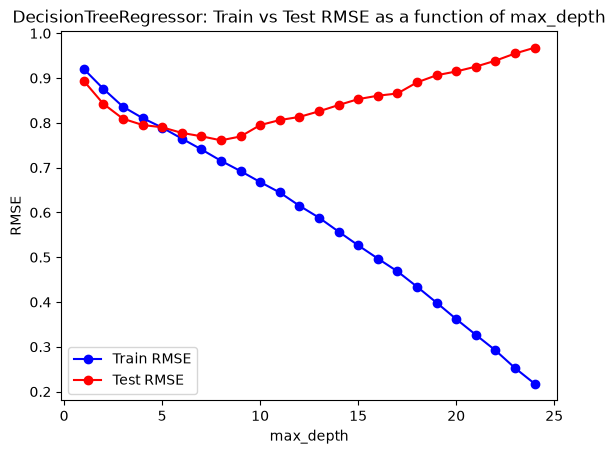

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import root_mean_squared_error

#1 we split the data 
X_train, X_test, y_train, y_test = train_test_split(X_num, y, test_size=0.2, random_state=42)

#  2 we test the depths (from 1 to 25) : 
depths = np.arange(1,25)
train_rmse_list = []
test_rmse_list = []

for d in depths :
    tree = DecisionTreeRegressor(max_depth=d, random_state=42) 
    tree.fit(X_train, y_train)

    # compute rmse for train and test :
    train_rmse_list.append(root_mean_squared_error(y_train,tree.predict(X_train)))
    test_rmse_list.append(root_mean_squared_error(y_test, tree.predict(X_test)))

# 3 find the best depth : 
best_depth = depths[np.argmin(test_rmse_list)]

print(f" Best depth is {best_depth} (RMSE Test: {min(test_rmse_list):.4f})")


# 4. plot
plt.plot(depths, train_rmse_list, label="Train RMSE", color="blue", marker ='o')
plt.plot(depths, test_rmse_list, label="Test RMSE", color="red", marker ='o')
plt.xlabel("max_depth")
plt.ylabel("RMSE")
plt.title("DecisionTreeRegressor: Train vs Test RMSE as a function of max_depth")
plt.legend()
plt.show()

This estimator recursively splits the features into non-overlapping regions using a simple binary condition.  To predict a value, it traverses the questions from roots to leaf based on its feature and finally takes the mean of the training target values falling in that leaf as the final prediction.

### Question 7: 

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# model without Standard Scaler we take the one from q6 (max_depth = 8) : 
tree_raw = DecisionTreeRegressor(max_depth=8, random_state=42)
tree_raw.fit(X_train, y_train)
rmse_raw = root_mean_squared_error(y_test, tree_raw.predict(X_test))

# model with standar scaler with a pipeline
tree_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('tree', DecisionTreeRegressor(max_depth=8, random_state=42))
])
tree_pipe.fit(X_train, y_train)
rmse_scaled =  root_mean_squared_error(y_test, tree_pipe.predict(X_test))

# Comparaison
print(f"RMSE without scaler : {rmse_raw:.6f}")
print(f"RMSE with scaler: {rmse_scaled:.6f}")
print(f"difference: {abs(rmse_raw - rmse_scaled):.2e}")


RMSE without scaler : 0.760979
RMSE with scaler: 0.760978
difference: 8.95e-07


##### Answer
The RMSE is identical with and without StandardScaler. 

This is expected because in Decision Trees : splits only depend on the order of the values, which is completely preserved by standardization. The tree therefore produces the exact same splits and predictions.

### Question 8 : 

In [7]:
from sklearn.linear_model import LinearRegression

#1 Linear Reg (lr) without scaling:
lr_raw = LinearRegression(fit_intercept=True)
lr_raw.fit(X_train, y_train)
rmse_raw = root_mean_squared_error(y_test, lr_raw.predict(X_test))

#2 Linear Reg (lr) with scaling:
lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LinearRegression(fit_intercept=True))
])
lr_pipe.fit(X_train, y_train)
rmse_scaled = root_mean_squared_error(y_test, lr_pipe.predict(X_test))

print(f"RMSE without scaler : {rmse_raw:.6f}")
print(f"RMSE with scaler: {rmse_scaled:.6f}")
print(f"difference: {abs(rmse_raw - rmse_scaled):.2e}")

RMSE without scaler : 0.858975
RMSE with scaler: 0.858975
difference: 2.22e-16


##### Answer

The RMSE is again identical with and without StandardScaler. 

(Scaling would only change the predictions if we used regularization like Ridge or Lasso).

### Question 9 : 

In [8]:
from sklearn.preprocessing import OneHotEncoder

cat_cols = ['Departure', 'Arrival']
ohe = OneHotEncoder()

X_cat_trans = ohe.fit_transform(df[cat_cols])

print("Categories inferred by the OneHotEncoder :")
for col, cats in zip(cat_cols, ohe.categories_):
    print(f"\n{col} ({len(cats)} categories) :\n{cats}")
# delete from memory
del X_cat_trans

Categories inferred by the OneHotEncoder :

Departure (20 categories) :
['ATL' 'BOS' 'CLT' 'DEN' 'DFW' 'DTW' 'EWR' 'IAH' 'JFK' 'LAS' 'LAX' 'LGA'
 'MCO' 'MIA' 'MSP' 'ORD' 'PHL' 'PHX' 'SEA' 'SFO']

Arrival (20 categories) :
['ATL' 'BOS' 'CLT' 'DEN' 'DFW' 'DTW' 'EWR' 'IAH' 'JFK' 'LAS' 'LAX' 'LGA'
 'MCO' 'MIA' 'MSP' 'ORD' 'PHL' 'PHX' 'SEA' 'SFO']


### Question 10 

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline 
from sklearn.preprocessing import StandardScaler, OneHotEncoder 

# 1 we list our columns
num_cols = list(X_num.columns)
cat_cols = ['Departure', 'Arrival']

# 2 we create X with all features (num + cat) and train 
X = df[num_cols + cat_cols]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3 preprocessor : scaler on nums and OneHot on airports
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(), cat_cols)
    ])

# 4  Pipeline: Preprocessor + RandomForest
rf_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('rf', RandomForestRegressor(random_state=42))
     ])


# 5 train and rmse to check what we did
rf_pipe.fit(X_train, y_train)
y_pred = rf_pipe.predict(X_test)

rmse_rf = root_mean_squared_error(y_test, y_pred)


print(f"Random Forest Test RMSE : {rmse_rf:.4f}")


Random Forest Test RMSE : 0.4701


### Question 11 : 

In [10]:
import time
from sklearn.model_selection import GridSearchCV

# 1 hyperparameters to test
param_grid = {
    'rf__n_estimators': [50, 100],
    'rf__max_depth': [10, 20, None]
}

# 2 GridSearchCV with 3-fold cross validation
grid = GridSearchCV(
    estimator= rf_pipe, # from question before
    param_grid=param_grid, 
    cv = 3, 
    scoring='neg_root_mean_squared_error', 
    n_jobs=-1
)

# 3 Train and time measurement 
t0 = time.time()
grid.fit(X_train, y_train)
duration = time.time() - t0

# prints 
print(f"Execution Time : {duration:.2f} seconds")
print("Best hyperparameters :", grid.best_params_)
print(f"Best cross val Rmse : {-grid.best_score_:.4f}")

rmse = root_mean_squared_error(y_test, grid.best_estimator_.predict(X_test))
print(f"Best RMSE for test : {rmse:.2f}")



Execution Time : 14.54 seconds
Best hyperparameters : {'rf__max_depth': None, 'rf__n_estimators': 100}
Best cross val Rmse : 0.5143
Best RMSE for test : 0.47


The GridSearch takes around 15 seconds. This is because it trains 6 hyperparameter combinations across 3 folds, meaning 18 Random Forest models in total (each with 50 to 100 decision trees). Using n_jobs=-1 parallelizes the training across CPU cores, which keeps the time reasonable.

### Question 12 : 

In [11]:
import joblib

# 1 
best_pipeline = grid.best_estimator_
best_model = best_pipeline.named_steps['rf']

# 2 save on the disk
joblib.dump(best_pipeline,'full_pipeline.joblib')
joblib.dump(best_model, 'best_model.joblib')

# 3 load from disk
loaded_pipeline = joblib.load('full_pipeline.joblib')
loaded_model = joblib.load('best_model.joblib')

# 4 test 
print("Test with loaded pipeline :", loaded_pipeline.predict(X_test[:2]))


Test with loaded pipeline : [11.01774383 10.13050934]


#### Why is dumping estimators useful?

1. Deployment in production: In real-world applications, a trained pipeline can be loaded directly into a backend/API  to serve live predictions without needing the training data or re-running the training script.
2. Time and compute savings: Training complex models on large datasets can take hours or days. Saving the trained weights allows instant reuse.
3. Reproducibility and Versioning: It allows saving exact snapshots of models to track performance over time or rollback if needed.

# K-nearest neighbors 

### Question 13 

Fitting a KNN has a time complexity of $\mathcal{O}(1)$ in time, as the algorithm simply stores the training data in memory without a parametric training phase, and $\mathcal{O}(d \cdot n)$ in space as we occupy n points with d features in memory. 


Predicting for a new point has a cost of $\mathcal{O}(d \cdot n)$, because it requires computing the distance between that point and all training samples, as we have n points and d features each time. 

### Question 14 : 

In [12]:
from sklearn.base import BaseEstimator, ClassifierMixin
from scipy.stats import mode

class KNearestNeighbor(BaseEstimator, ClassifierMixin):

    def __init__(self, n_neighbors=5):
        self.n_neighbors = n_neighbors

    def fit(self, X, y):
        self.X_train_ = np.asarray(X)
        self.y_train_ = np.asarray(y)
        return self

    def predict(self, X):
        X = np.asarray(X)
        predictions = []
        
        for x in X:
            dist = np.linalg.norm(self.X_train_ - x, axis = 1)
            k_indices = np.argsort(dist)[:self.n_neighbors]
            k_nearest_labels = self.y_train_[k_indices]
            most_common = mode(k_nearest_labels, keepdims=True).mode[0]          # mode return an object with 2 informations :
            predictions.append(most_common)                                       # 1- .mode (value most frequent)
                                                                                  # 2. .count (number of times it appears)
        
        return np.array(predictions)

### Question 15` : 

Shape of X:  (192, 2)
Shape of y:  (192,)
[1. 2. 3.]


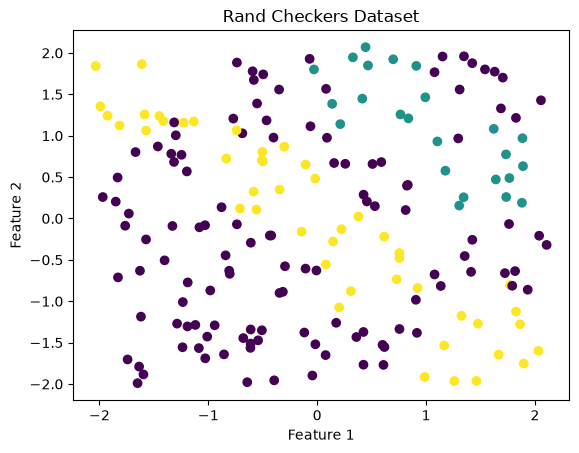

In [13]:
import matplotlib.pyplot as plt
from utils import rand_checkers
X, y = rand_checkers(n_samples=200, sigma=0.1, random_state=42)
print('Shape of X: ', np.shape(X))
print('Shape of y: ', np.shape(y))
print(np.unique(y))
plt.scatter(X[:,0],X[:,1], c=y)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Rand Checkers Dataset")
plt.show()

#### Description of the data:
The dataset is composed of 192 samples with 2 numerical features. 
It is a 3-class classification problem (labels 1, 2, and 3).
Because the classes alternate in a grid, the decision boundaries are non-linear, which is well-suited for a KNN classifier.

### Question 16: 

30
30
30


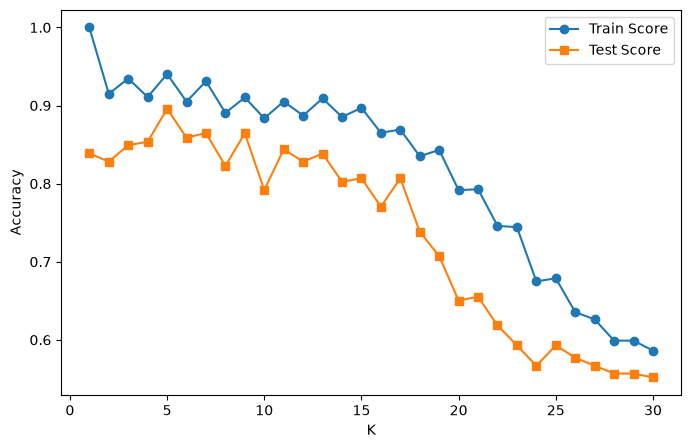

In [14]:
from sklearn.model_selection import cross_validate

k_values = range(1, 31)

train_scores = []
test_scores = []

for k in k_values:
    model = KNearestNeighbor(n_neighbors=k)

    scores = cross_validate(model, X, y, scoring = 'accuracy', cv=10, return_train_score=True)

    train_scores.append(np.mean(scores['train_score']))
    test_scores.append(np.mean(scores['test_score'] ))

print(len(k_values))
print(len(train_scores))
print(len(test_scores))


plt.figure(figsize=(8, 5))
plt.plot(k_values, train_scores, label='Train Score', marker='o')
plt.plot(k_values, test_scores, label='Test Score', marker='s')
plt.xlabel('K')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

- For k=1, the model overfits: train accuracy is 100% because every point is its own nearest neighbor, but test accuracy is suboptimal due to sensitivity to noise.
- The best test performance is reached around k=5 (accuracy ~90%), which offers the best trade-off by smoothing out local noise while respecting the grid structure.
- For large values of k (k > 15), the model underfits: the neighborhood becomes larger than the individual checkerboard squares, mixing different classes and causing both train and test accuracy to drop.

### Question 17: 

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression 
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier


df_adult = fetch_openml('adult', version=2, as_frame=True)
X = df_adult.data
y = df_adult.target

cat_cols = list(X.select_dtypes(include=['category', 'object']).columns)
num_cols = list(X.select_dtypes(include=['number']).columns)

print('cat_cols: ', cat_cols)
print('num_cols: ', num_cols)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

preprocessor_one_hot = ColumnTransformer(
    transformers = [
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output= False), cat_cols) # In most cases we put these parameters for OHE
    ]
)

preprocessor_ord = ColumnTransformer(
    transformers = [
        ('num', StandardScaler(), num_cols),
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', encoded_missing_value=-1, unknown_value=-1), cat_cols) # we put -1 for Nan Values
    ]
)
#----- Logistic Regression -----------
# version One-Hot: 
pipe_lr_ohe = Pipeline([
    ('prep', preprocessor_one_hot),
    ('clf', LogisticRegression(max_iter=1000))
])
pipe_lr_ohe.fit(X_train, y_train)
print(f"Logistic Regression One-Hot test score : {pipe_lr_ohe.score(X_test,y_test):.3f}")

# Version Ordinal: 
pipe_lr_ord = Pipeline([
    ('prep', preprocessor_ord),
    ('clf', LogisticRegression(max_iter=1000))
])
pipe_lr_ord.fit(X_train, y_train)
print(f"Logistic Regression Ordinal test score : {pipe_lr_ord.score(X_test,y_test):.3f}")

# ------- RandomForestClassifier ---------
# version One-Hot: 
pipe_rf_ohe = Pipeline([
    ('prep', preprocessor_one_hot),
    ('rf', RandomForestClassifier(n_jobs=-1, random_state=42))
])
pipe_rf_ohe.fit(X_train, y_train)
print(f"RandomForestClassifier One-Hot : {pipe_rf_ohe.score(X_test, y_test):.3f}")

# Version Ordinal :
pipe_rf_ord = Pipeline([
    ('prep', preprocessor_ord),
    ('rf', RandomForestClassifier(n_jobs=-1, random_state=42))
])
pipe_rf_ord.fit(X_train, y_train)
print(f"RandomForestClassifier Ordinal : {pipe_rf_ord.score(X_test, y_test):.3f}")
# ------- HistGradientBoostingClassifier ---------
# version One-Hot: 
pipe_hgbc_ohe = Pipeline([
    ('prep', preprocessor_one_hot),
    ('hgbc', HistGradientBoostingClassifier(random_state=42))
])
pipe_hgbc_ohe.fit(X_train, y_train)
print(f"HistGradientBoostingClassifier OHE : {pipe_hgbc_ohe.score(X_test, y_test):.3f}")
# Version Ordinal :
pipe_hgbc_ord = Pipeline([
    ('prep', preprocessor_ord),
    ('hgbc', HistGradientBoostingClassifier(random_state=42))
])
pipe_hgbc_ord.fit(X_train, y_train)
print(f"HistGradientBoostingClassifier Ordinal : {pipe_hgbc_ord.score(X_test, y_test):.3f}")


cat_cols:  ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
num_cols:  ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Logistic Regression One-Hot test score : 0.857
Logistic Regression Ordinal test score : 0.827
RandomForestClassifier One-Hot : 0.860
RandomForestClassifier Ordinal : 0.865
HistGradientBoostingClassifier OHE : 0.879
HistGradientBoostingClassifier Ordinal : 0.879


- Logistic Regression: One-Hot encoding works significantly better (0.86 vs 0.83). Since it is a linear model, ordinal encoding falsely imposes an arbitrary numerical order and distance between categories (ex: jobs or countries), hurting performance.
- Random Forest and HistGradientBoosting: Both models perform equally well with One-Hot and Ordinal encoding (0.86 for RF, 0.88 for HGB). Tree-based models only make threshold splits and do not assume linear relationships.
- Efficiency: For tree-based models, Ordinal encoding is preferred in practice because it avoids expanding the feature space (14 columns instead of ~100 with One-Hot), saving memory and training time.
- Best model: HistGradientBoosting achieves the best accuracy (0.88).

We could also code with a for loop (i still keep the one above because it helped for understanding) : like bellow it is an other way to do it but more optimal.

In [16]:
# 1  We list our 3 model in a dict
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000), 
    'Random Forest': RandomForestClassifier(n_jobs=-1, random_state=42),  
    'Hist Gradient Boosting': HistGradientBoostingClassifier(random_state=42)
} 

# 2 Same with our 2 processors
preprocessors = {
    'One-Hot': preprocessor_one_hot, 
    'Ordinal': preprocessor_ord
} 

# 3    3 models * 2 preprocess = 6 tests
for model_name, model in models.items():
    for prep_name, prep in preprocessors.items():
        pipe = Pipeline([
            ('prep', prep),
            ('clf', model)
        ])
        pipe.fit(X_train, y_train)
        score = pipe.score(X_test, y_test)
        print(f"{model_name:<25} | {prep_name:<8} : {score:.4f}")   # way of printing better 

Logistic Regression       | One-Hot  : 0.8570
Logistic Regression       | Ordinal  : 0.8271
Random Forest             | One-Hot  : 0.8601
Random Forest             | Ordinal  : 0.8648
Hist Gradient Boosting    | One-Hot  : 0.8793
Hist Gradient Boosting    | Ordinal  : 0.8786


### Question 18 : 

In [17]:
import optuna
from sklearn.model_selection import cross_val_score

# 1. Optimisation avec Ordinal Encoder
def objective1(trial):
    learning_rate = trial.suggest_float('learning_rate', 1e-3, 1.0, log=True)
    pipe = Pipeline([
        ('prep', preprocessor_ord), 
        ('model', HistGradientBoostingClassifier(learning_rate=learning_rate, random_state=42))
    ])
    return np.mean(cross_val_score(pipe, X, y, cv=5, scoring="accuracy"))

study1 = optuna.create_study(direction='maximize')
study1.optimize(objective1, n_trials=30)

# 2. Optimisation avec One-Hot Encoder
def objective2(trial):
    learning_rate = trial.suggest_float('learning_rate', 1e-3, 1.0, log=True)
    pipe = Pipeline([
        ('prep', preprocessor_one_hot), 
        ('model', HistGradientBoostingClassifier(learning_rate=learning_rate, random_state=42))
    ])
    return np.mean(cross_val_score(pipe, X, y, cv=5, scoring="accuracy"))

study2 = optuna.create_study(direction='maximize')
study2.optimize(objective2, n_trials=30)

# 3. Comparaison avec les resultats de la question 17
print("\n--- Comparison ---")
print("Logistic Regression     | One-Hot : 0.8570")
print("Logistic Regression     | Ordinal : 0.8271")
print("Random Forest           | One-Hot : 0.8651")
print("Random Forest           | Ordinal : 0.8648")
print(f"HGB + Optuna            | Ordinal : {study1.best_value:.4f}")
print(f"HGB + Optuna            | One-Hot : {study2.best_value:.4f}")

[I 2026-11-11 20:51:14,013] A new study created in memory with name: no-name-7024aaae-53de-44b0-8c02-64f0b606a67e
[I 2026-11-11 20:51:23,614] Trial 0 finished with value: 0.8743295012411606 and parameters: {'learning_rate': 0.09432550443499917}. Best is trial 0 with value: 0.8743295012411606.
[I 2026-11-11 20:51:33,260] Trial 1 finished with value: 0.8200319790938073 and parameters: {'learning_rate': 0.006111079495374779}. Best is trial 0 with value: 0.8743295012411606.
[I 2026-11-11 20:51:35,533] Trial 2 finished with value: 0.8677982694258668 and parameters: {'learning_rate': 0.6454021957280115}. Best is trial 0 with value: 0.8743295012411606.
[I 2026-11-11 20:51:45,208] Trial 3 finished with value: 0.7607182362198229 and parameters: {'learning_rate': 0.002588233983378722}. Best is trial 0 with value: 0.8743295012411606.
[I 2026-11-11 20:51:54,949] Trial 4 finished with value: 0.7607182362198229 and parameters: {'learning_rate': 0.0018130780313893305}. Best is trial 0 with value: 0.8


--- Comparison ---
Logistic Regression     | One-Hot : 0.8570
Logistic Regression     | Ordinal : 0.8271
Random Forest           | One-Hot : 0.8651
Random Forest           | Ordinal : 0.8648
HGB + Optuna            | Ordinal : 0.8743
HGB + Optuna            | One-Hot : 0.8738


- HistGradientBoosting tuned with Optuna reaches the best accuracy (~87.4%), outperforming both Random Forest (86.5%) and Logistic Regression (85.7%).
- Tuning the learning rate improves performance over the default value, and both Ordinal and One-Hot encodings give similar results.

### Question 19 : 

In [18]:
salary_X = pd.read_csv('./skrub_data_lab3/salary_X.csv', index_col=0)
salary_y = pd.read_csv('./skrub_data_lab3/salary_y.csv', index_col=0)

salary_X.head()


,gender,department,department_name,division,assignment_category,employee_position_title,date_first_hired,year_first_hired
0,F,POL,Department of Police,MSB Information Mgmt and Tech Division Records...,Fulltime-Regular,Office Services Coordinator,09/22/1986,1986
1,M,POL,Department of Police,ISB Major Crimes Division Fugitive Section,Fulltime-Regular,Master Police Officer,09/12/1988,1988
2,F,HHS,Department of Health and Human Services,Adult Protective and Case Management Services,Fulltime-Regular,Social Worker IV,11/19/1989,1989
3,M,COR,Correction and Rehabilitation,PRRS Facility and Security,Fulltime-Regular,Resident Supervisor II,05/05/2014,2014
4,M,HCA,Department of Housing and Community Affairs,Affordable Housing Programs,Fulltime-Regular,Planning Specialist III,03/05/2007,2007


This dataset is about predicting the current annual salary (a continuous target, so a supervised regression problem) of public employees from their characteristics: gender, department and division, job title, assignment category, and hiring date (seniority).

### Question 20 : 

In [19]:
salary_X.nunique()

gender                        2
department                   37
department_name              37
division                    694
assignment_category           2
employee_position_title     443
date_first_hired           2264
year_first_hired             51
dtype: int64


The columns division, employee_position_title and date_first_hired may cause issues in an OneHotEncoder as they would produce thousands of mostly-zero columns. This increases memory use and computation time and causes overfitting.
Also, modalities unseen at test time carry no information so it would cause a problem.
Finally, date_first_hired is a date stored as a string, so treating it as a category makes no sense: it should be converted to a datetime so that order and time gaps can be used.

### Question 21 : 

In [20]:
salary_X['employee_position_title'].value_counts().head(20)

employee_position_title
Bus Operator                               638
Police Officer III                         620
Firefighter/Rescuer III                    388
Manager III                                243
Firefighter/Rescuer II                     219
Master Firefighter/Rescuer                 218
Office Services Coordinator                207
School Health Room Technician I            204
Police Officer II                          171
Community Health Nurse II                  165
Crossing Guard                             161
Correctional Officer III (Corporal)        151
Program Manager II                         145
Income Assistance Program Specialist II    142
Fire/Rescue Captain                        141
Police Sergeant                            140
Liquor Store Clerk I                       128
Manager II                                 121
Principal Administrative Aide              120
Fire/Rescue Lieutenant                     119
Name: count, dtype: int64

- **Distance:** Yes, a textual distance based on shared words (e.g. "Police Officer I" is close to "Police Officer II", but far from "Library Assistant").
- **Ordering:** Partially ordered: there is a seniority hierarchy within job families (I < II < III), but no global ordering across different jobs.
- **Encoding:** GapEncoder from skrub, which captures similarities `between strings using subwords (n-grams).

### Question 22 : 

In [21]:
from skrub import GapEncoder

X = [["Math, optimization"], ["mathematics"], ["maths, ml"], ["ml.maths"],
     ["machine learning"], ["physics"], ["phy"],
     ["statistical physics"], ["computational phys."]]

enc = GapEncoder(n_components=2, random_state=42)
X_trans = enc.fit_transform(pd.DataFrame(X))
X_trans

clean = enc.transform(pd.DataFrame([["physics"]]))
dirty = enc.transform(pd.DataFrame([["physcis"]])) # faute de frappe : c avant i

print("Propre :")
print(clean)
print("\nAvec faute de frappe :")
print(dirty)
enc.get_feature_names_out()

  

Propre :
   learning, machine, mathematics  computational, statistical, physics
0                        0.003871                             0.491781

Avec faute de frappe :
   learning, machine, mathematics  computational, statistical, physics
0                         0.00333                             0.231453


['learning, machine, mathematics', 'computational, statistical, physics']

- Both "physics" and the typo "physcis" activate the physics topic, showing that the encoder is robust to spelling mistakes.
- This is a good thing: it captures meaning despite typos, whereas One-Hot would output all zeros.
- n_components is the number of latent topics to extract (here 2: Maths and Physics).
- The learned topics are printed with enc.get_feature_names_out().

### Question 23 : 

In [22]:
from skrub import TableVectorizer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline

final_pipeline = Pipeline([
    ('prep', TableVectorizer()),
    ('hgbr', HistGradientBoostingRegressor(random_state=42))
])
final_pipeline.fit(salary_X, salary_y['current_annual_salary'])


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('hgbr', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0",list,"['gender', 'de...nt', 'de...me', 'di...on', ...]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"low_cardinality low_cardinality: transformer, ""passthrough"" or ""drop"", default=OneHotEncoder instanceThe transformer for string or categorical columns with strictly fewer than``cardinality_threshold`` unique values. By default, we use a:class:`~sklearn.preprocessing.OneHotEncoder` that ignores unknown categoriesand drop one of the transformed columns if the feature contains only 2categories.",OneHotEncoder..._output=False)
,"high_cardinality high_cardinality: transformer, ""passthrough"" or ""drop"", default=StringEncoder instanceThe transformer for string or categorical columns with at least``cardinality_threshold`` unique values. The default is a:class:`~skrub.StringEncoder` with 30 components (30 output columns for eachinput)... versionchanged:: 0.6.0 The default ``high_cardinality`` encoder has been changed from :class:`~skrub.GapEncoder` to :class:`~skrub.StringEncoder`.",StringEncoder()
,"numeric numeric: transformer, ""passthrough"" or ""drop"", default=""passthrough""The transformer for numeric columns (floats, ints, booleans).",PassThrough()
,"datetime datetime: transformer, ""passthrough"" or ""drop"", default=DatetimeEncoder instanceThe transformer for date and datetime columns. By default, we use a:class:`~skrub.DatetimeEncoder`.",DatetimeEncoder()


In [23]:
table_vec = final_pipeline.steps[0][1]
table_vec.transformers_

{'year_first_hired': PassThrough(),
 'date_first_hired': DatetimeEncoder(),
 'gender': OneHotEncoder(drop='if_binary', dtype='float32', handle_unknown='ignore',
               sparse_output=False),
 'department': OneHotEncoder(drop='if_binary', dtype='float32', handle_unknown='ignore',
               sparse_output=False),
 'department_name': OneHotEncoder(drop='if_binary', dtype='float32', handle_unknown='ignore',
               sparse_output=False),
 'assignment_category': OneHotEncoder(drop='if_binary', dtype='float32', handle_unknown='ignore',
               sparse_output=False),
 'division': StringEncoder(),
 'employee_position_title': StringEncoder()}

- TableVectorizer automatically checked each column and applied the right encoder: PassThrough for numbers, DatetimeEncoder for the date, OneHot for simple categories, and StringEncoder for complex job titles. It then fitted all these encoders.
- HistGradientBoostingRegressor trained an ensemble of boosted trees on the encoded data to predict salaries.